In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
# Risk Factor Returns

In [12]:
np.random.seed(42)

n_days = 250
risk_factors = {
     "Equity":           {"vol": 0.02,  "LH": 20},
    "Rates":            {"vol": 0.01,  "LH": 40},
    "CreditSpread":     {"vol": 0.015, "LH": 60},
    "FX_Majors":        {"vol": 0.012, "LH": 20},
    "Commodity_Oil":    {"vol": 0.025, "LH": 60},
    "Vol_Index":        {"vol": 0.03,  "LH": 60},
    
    
}

df = pd.DataFrame({
    rf: np.random.normal(0, risk_factors[rf]["vol"], n_days)
    for rf in risk_factors
})

df


,Equity,Rates,CreditSpread,FX_Majors,Commodity_Oil,Vol_Index
0,0.009934,-0.012609,0.013893,-0.011079,0.034984,0.009926
1,-0.002765,0.009179,0.028641,-0.016220,0.023116,0.025006
2,0.012954,0.021222,-0.020979,-0.011710,0.001491,-0.059812
3,0.030461,0.010325,0.008445,0.012644,-0.016173,0.011222
4,-0.004683,-0.015194,-0.009760,-0.011393,0.017456,0.036830
...,...,...,...,...,...,...
245,-0.006690,0.005389,-0.010886,-0.003373,-0.030599,0.060183
246,-0.009499,-0.010372,0.002802,0.021572,0.000852,0.061845
247,-0.013067,-0.001903,-0.011331,0.007690,-0.019249,0.036251
248,0.035309,-0.008756,-0.009173,-0.006854,0.005845,0.030722


In [ ]:
# FRTB Liquidity Horizon Scaling

In [47]:
def expected_shortfall(returns, alpha=0.975):
    var = np.percentile(returns, (1-alpha)*100)
    es = returns[returns < var].mean()
    return abs(es)

bucket_es = {}
for rf in df.columns:
    base_es = expected_shortfall(df[rf])
    LH = risk_factors[rf]["LH"]
    scaled_es = base_es * np.sqrt(LH / 10)
    bucket_es[rf] = scaled_es

bucket_es

bucket_es = {k: float(v) for k, v in bucket_es.items()}
bucket_es

{'Equity': 0.05774615158970197,
 'Rates': 0.044241673693885875,
 'CreditSpread': 0.0851586827441207,
 'FX_Majors': 0.03241147014901001,
 'Commodity_Oil': 0.13847022470794765,
 'Vol_Index': 0.15819803651786923}

In [ ]:
# Expected Shortfall

In [49]:
total_es = np.sqrt(np.sum(np.array(list(bucket_es.values())) ** 2))

total_es

np.float64(0.24040605285094152)

In [ ]:
# Scenario Analysis

In [33]:
weights = {
    "Equity": 0.25,
    "Rates": 0.20,
    "Commodity_Oil": 0.10
}

scenario_impacts = {}

for name, shock in scenarios.items():
    impact = 0
    for rf, shock_value in shock.items():
        if rf in weights:
            impact += weights[rf] * shock_value
    scenario_impacts[name] = impact

scenario_impacts



{'Equity -15%': -0.0375, 'Rates +200bps': -0.004, 'Oil +25% Spike': 0.025}

In [45]:
# Individual Capital Charge

In [42]:

weights = {
    "Equity": 0.25,
    "Rates": 0.20,
    "CreditSpread": 0.20,
    "FX_Majors": 0.15,
    "Commodity_Oil": 0.10,
    "Vol_Index":0.10,
}

weights = {rf: weights.get(rf, 0.10) for rf in bucket_es}

# Individual capital charge
individual_capital = {
    rf: bucket_es[rf] * weights[rf] * 1.5
    for rf in bucket_es
}

individual_capital

individual_capital = {k: float(v) for k, v in individual_capital.items()}
individual_capital


{'Equity': 0.021654806846138238,
 'Rates': 0.013272502108165763,
 'CreditSpread': 0.02554760482323621,
 'FX_Majors': 0.007292580783527252,
 'Commodity_Oil': 0.020770533706192147,
 'Vol_Index': 0.023729705477680385}

In [46]:
# Portfolio Capital Charge

In [43]:
portfolio_es = sum(bucket_es[rf] * weights[rf] for rf in weights)
capital_charge = portfolio_es * 1.5   
capital_charge

np.float64(0.11226773374494001)

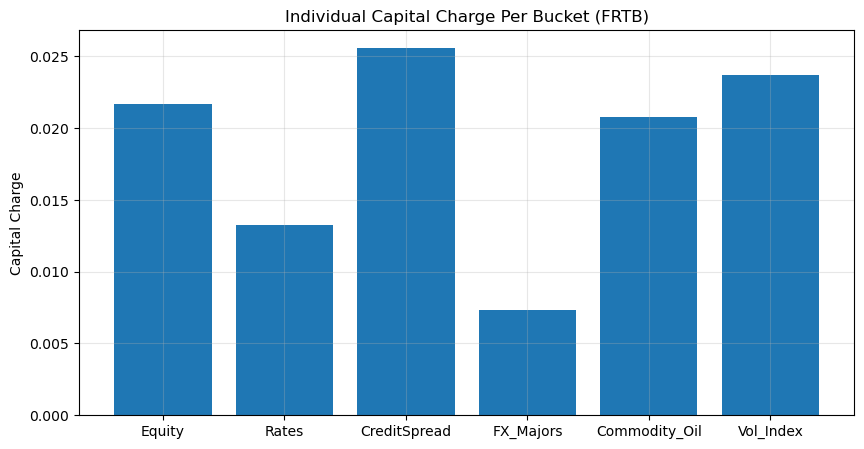

In [44]:
plt.figure(figsize=(10,5))
plt.bar(individual_capital.keys(), individual_capital.values())
plt.title("Individual Capital Charge Per Bucket (FRTB)")
plt.ylabel("Capital Charge")
plt.grid(alpha=0.3)
plt.show()
